# Machine Learning - Week 3: ShopSegments - Customer Segmentation & Product Recommender

**Developer:** Muhammad Azlan  
**Project Goal:** Segment e-commerce customers using unsupervised learning (RFM + K-Means/UMAP) and build a personalized product recommendation engine.

---

## Day 1: Data Loading, Cleaning & RFM Feature Engineering

In this section, we will load the dataset `/content/online_retail_II.xlsx`, clean the transactions (handle missing values, remove cancellations/returns), and build basic RFM (Recency, Frequency, Monetary) metrics.

### Day 1 Deliverables & Tasks Checklist:
- [ ] **Load Dataset**: Safely load `/content/online_retail_II.xlsx` handling format exceptions.
- [ ] **Data Cleaning**: Handle missing `Customer ID`, drop records with canceled invoices (Invoice starts with 'C'), clean negative/zero `Quantity` and `Price` values.
- [ ] **Feature Engineering**: Generate Total Spend per order, and compute standard RFM metrics (Recency, Frequency, Monetary) per customer.

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# TODO: Load '/content/online_retail_II.xlsx' using pandas.
# Tip: If you get a BadZipFile error, inspect the format or try pd.read_excel(dataset_path, engine='xlrd') or pd.read_csv if it is a CSV.

In [27]:
# 1. Load the Excel file and combine all sheets
file_path = 'online_retail_II.xlsx'
xls = pd.ExcelFile(file_path)

dfs = []
for sheet in xls.sheet_names:
    temp_df = pd.read_excel(file_path, sheet_name=sheet)
    dfs.append(temp_df)

In [28]:
df = pd.concat(dfs, ignore_index=True)
print(f"Original shape: {df.shape}")

Original shape: (1067371, 8)


In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB


In [30]:
df.shape

(1067371, 8)

In [31]:
df.describe()

,Quantity,InvoiceDate,Price,Customer ID
count,1.067371e+06,1067371,1.067371e+06,824364.000000
mean,9.938898e+00,2011-01-02 21:13:55.394028544,4.649388e+00,15324.638504
min,-8.099500e+04,2009-12-01 07:45:00,-5.359436e+04,12346.000000
25%,1.000000e+00,2010-07-09 09:46:00,1.250000e+00,13975.000000
50%,3.000000e+00,2010-12-07 15:28:00,2.100000e+00,15255.000000
75%,1.000000e+01,2011-07-22 10:23:00,4.150000e+00,16797.000000
max,8.099500e+04,2011-12-09 12:50:00,3.897000e+04,18287.000000
std,1.727058e+02,NaN,1.235531e+02,1697.464450


### Data Cleaning & Preprocessing
Filter out cancelled orders (typically Invoice containing 'C'), handle null Customer IDs, and process prices or quantities <= 0.

In [32]:
# TODO: Clean the dataset
# 1. Drop rows with missing Customer IDs
# 2. Exclude cancelled orders (Invoices starting with 'C')
# 3. Filter out non-positive quantities and prices
# 4. Calculate Total Spend per transaction

In [33]:
df.isnull().sum()

,0
Invoice,0
StockCode,0
Description,4382
Quantity,0
InvoiceDate,0
Price,0
Customer ID,243007
Country,0


In [34]:
# 2. Drop rows with missing Customer IDs
df = df.dropna(subset=['Customer ID'])

In [35]:
# 3. Exclude cancelled orders (Invoices starting with 'C')
df['Invoice_str'] = df['Invoice'].astype(str)
df = df[~df['Invoice_str'].str.startswith('C')]

In [36]:
# 4. Filter out non-positive quantities and prices
df = df[(df['Quantity'] > 0) & (df['Price'] > 0)]

In [37]:
# 5. Calculate Total Spend per transaction (Quantity * Price)
df['TotalSpend'] = df['Quantity'] * df['Price']

In [38]:
# Clean up temporary helper column if needed
df = df.drop(columns=['Invoice_str'])

In [39]:
print(f"Cleaned dataset shape: {df.shape}")
print(df.head())

Cleaned dataset shape: (805549, 9)
  Invoice StockCode                          Description  Quantity  \
0  489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1  489434    79323P                   PINK CHERRY LIGHTS        12   
2  489434    79323W                  WHITE CHERRY LIGHTS        12   
3  489434     22041         RECORD FRAME 7" SINGLE SIZE         48   
4  489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24   

          InvoiceDate  Price  Customer ID         Country  TotalSpend  
0 2009-12-01 07:45:00   6.95      13085.0  United Kingdom        83.4  
1 2009-12-01 07:45:00   6.75      13085.0  United Kingdom        81.0  
2 2009-12-01 07:45:00   6.75      13085.0  United Kingdom        81.0  
3 2009-12-01 07:45:00   2.10      13085.0  United Kingdom       100.8  
4 2009-12-01 07:45:00   1.25      13085.0  United Kingdom        30.0  


### Build RFM Table
Calculate Recency (days since last purchase), Frequency (number of unique invoices), and Monetary (total spend) for each customer.

In [40]:
# TODO: Calculate RFM metrics per customer
# 1. Recency: days since the last purchase relative to a reference date
# 2. Frequency: number of unique transactions per customer
# 3. Monetary: total monetary value spent

In [41]:
# 1. Reference date set karein (Dataset ki sab se aakhri date + 1 day, taake recency positive aaye)
reference_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

# 2. RFM Calculation per Customer
rfm_df = df.groupby('Customer ID').agg({
    'InvoiceDate': lambda x: (reference_date - x.max()).days, # Recency: Aakhri purchase ke baad kitne din guzre
    'Invoice': 'nunique',                                      # Frequency: Unique transactions ki tadad
    'TotalSpend': 'sum'                                        # Monetary: Total spend kiya gaya paisa
}).reset_index()

# 3. Columns ke naam rename kar dein taake samajhne mein aasaani ho
rfm_df.columns = ['CustomerID', 'Recency', 'Frequency', 'Monetary']

print(rfm_df.head())

   CustomerID  Recency  Frequency  Monetary
0     12346.0      326         12  77556.46
1     12347.0        2          8   5633.32
2     12348.0       75          5   2019.40
3     12349.0       19          4   4428.69
4     12350.0      310          1    334.40


## Day 2: Scaling, Log Transforms & Clustering

Since RFM metrics are typically heavily skewed, we must apply logarithmic transformation or PowerTransformer, scale features, and execute K-Means/GMM clustering while validating with Silhouette / Elbow methods.

### Day 2 Deliverables & Tasks Checklist:
- [ ] **Distribution Analysis**: Check skewness of RFM distributions.
- [ ] **Log Transform**: Apply `log1p` or non-linear scaling transformations to normalize heavily skewed metrics.
- [ ] **Standardization**: Use `StandardScaler` to align features onto a shared scale.
- [ ] **K-Means / GMM Clustering**: Fit models with $K \in [2, 8]$.
- [ ] **Validation Metrics**: Evaluate inertia (Elbow method) and Silhouette scores to justify your final choice of cluster count.

In [42]:
# TODO: Apply Transformations and Scale Features
# 1. Apply log transforms (or PowerTransformer) to reduce heavy skewness in RFM
# 2. Standardize scaled values using StandardScaler
# 3. Fit K-Means over a range of K (e.g., 2 to 8) and plot Elbow/Silhouette curves to justify your cluster choice

In [43]:
from sklearn.preprocessing import StandardScaler

# 1. Check skewness visually or mathematically, apply Log Transformation to handle heavy outliers
rfm_log = pd.DataFrame()
rfm_log['Recency'] = np.log1p(rfm_df['Recency'])
rfm_log['Frequency'] = np.log1p(rfm_df['Frequency'])
rfm_log['Monetary'] = np.log1p(rfm_df['Monetary'])

# 2. Scale the features (Mean=0, Variance=1)
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

# Convert back to DataFrame for convenience
rfm_scaled_df = pd.DataFrame(rfm_scaled, columns=['Recency', 'Frequency', 'Monetary'])
print("Scaled RFM Data Sample:")
print(rfm_scaled_df.head())

Scaled RFM Data Sample:
    Recency  Frequency  Monetary
0  0.856701   1.254496  3.186625
1 -2.151979   0.800166  1.297127
2 -0.079138   0.299207  0.558100
3 -0.935308   0.073946  1.123790
4  0.824527  -1.058146 -0.735888


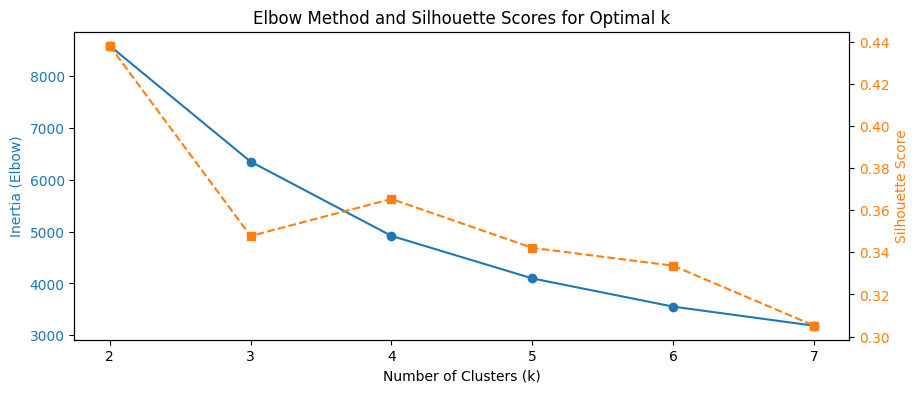

In [44]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia = []
silhouette_scores = []
K_range = range(2, 8)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(rfm_scaled)

    inertia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(rfm_scaled, cluster_labels))

# Plotting Elbow Method & Silhouette Scores
fig, ax1 = plt.subplots(figsize=(10, 4))

ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Inertia (Elbow)', color='tab:blue')
ax1.plot(K_range, inertia, marker='o', color='tab:blue', label='Inertia')
ax1.tick_params(axis='y', labelcolor='tab:blue')

ax2 = ax1.twinx()
ax2.set_ylabel('Silhouette Score', color='tab:orange')
ax2.plot(K_range, silhouette_scores, marker='s', color='tab:orange', linestyle='--', label='Silhouette Score')
ax2.tick_params(axis='y', labelcolor='tab:orange')

plt.title('Elbow Method and Silhouette Scores for Optimal k')
plt.show()

In [45]:
# Let's choose k = 4 (or 5 based on business interpretation)
optimal_k = 4
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
rfm_df['Cluster'] = kmeans.fit_predict(rfm_scaled)

# Let's see the average RFM values for each cluster to understand them
cluster_summary = rfm_df.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': ['mean', 'count']
}).round(2)

print("Cluster Summary:")
print(cluster_summary)

Cluster Summary:
        Recency Frequency  Monetary      
           mean      mean      mean count
Cluster                                  
0         27.43     19.34  11014.37  1188
1        395.86      1.38    325.75  1974
2        227.87      5.10   2002.10  1465
3         28.44      3.04    865.11  1251


## Day 3: Dimensionality Reduction (UMAP/PCA) & Visualizing Segments

Use UMAP or PCA to project clustered high-dimensional data into a interactive 2D visualization.

### Day 3 Deliverables & Tasks Checklist:
- [ ] **UMAP/PCA Embeddings**: Project the scaled features into a 2D coordinates space using PCA or UMAP.
- [ ] **Interactive Visualization**: Construct an interactive Plotly scatter plot showing customer segments with tooltips (displaying original RFM scores).
- [ ] **Segment Profiles**: Analyze cluster statistics (mean values, total spend) and assign descriptive marketing segment names (e.g., Champions, At Risk).

In [46]:
# TODO: Segment Naming and Visualisation
# 1. Fit your final chosen K-Means model on the scaled data
# 2. Assign cluster labels to the customers
# 3. Project features to 2D using UMAP or PCA and plot using an interactive tool like Plotly
# 4. Analyze profile cards / statistics per cluster to give them meaningful business names

In [47]:
import umap

# UMAP model initialize karein
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42)
embedding = reducer.fit_transform(rfm_scaled)

# UMAP coordinates ko rfm_df mein add karein
rfm_df['UMAP1'] = embedding[:, 0]
rfm_df['UMAP2'] = embedding[:, 1]

print("UMAP coordinates added successfully. Shape:", embedding.shape)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP coordinates added successfully. Shape: (5878, 2)


In [48]:
import plotly.express as px

# Clusters ko meaningful names assign karne ke liye mapping dictionary banate hain
# Aapke cluster summary ke mutabiq:
# Cluster 0: Kam Recency (haalia active), High Frequency, Very High Monetary -> 'Champions'
# Cluster 1: Bohat Ziada Recency (inactive), Low Frequency, Low Monetary -> 'Lost / Hibernating'
# Cluster 2: Medium Recency, Medium Frequency, Medium Monetary -> 'At Risk / Potential Loyalists'
# Cluster 3: Low Recency (haalia active), Low Frequency, Low Monetary -> 'Recent / New Customers'

cluster_names = {
    0: 'Champions',
    1: 'Lost',
    2: 'At Risk',
    3: 'New Customers'
}

rfm_df['Segment'] = rfm_df['Cluster'].map(cluster_names)

# Plotly Scatter Plot
fig = px.scatter(
    rfm_df,
    x='UMAP1',
    y='UMAP2',
    color='Segment',
    hover_data=['CustomerID', 'Recency', 'Frequency', 'Monetary'],
    title='ShopSegments: Customer Segmentation Map (UMAP)',
    template='plotly_white'
)

fig.show()

## Day 4: Collaborative Filtering & Product Recommendation (ALS)

Build the user-item interaction matrix, set up alternative least squares (ALS) or item-based collaborative filtering, and measure performance offline using hold-out evaluation.

### Day 4 Deliverables & Tasks Checklist:
- [ ] **Interaction Matrix**: Construct a sparse user-item matrix of purchase quantities.
- [ ] **Collaborative Filtering Model**: Train an Alternating Least Squares (ALS) or item-based collaborative filtering model.
- [ ] **Evaluation**: Perform offline split, evaluate using appropriate metrics like Precision@10 or Recall@10 on a validation subset.

In [49]:
# TODO: Recommender System
# 1. Build a sparse user-item interaction matrix
# 2. Implement collaborative filtering (e.g., ALS using implicit, or item-based collaborative filtering)
# 3. Evaluate the recommender offline (Precision@10 or Recall@10) on a hold-out test set
# 4. Create a fallback logic for cold-start (new) customers using popular products

In [53]:
pip install implicit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.6/7.6 MB 40.7 MB/s eta 0:00:00


In [61]:
import numpy as np, pandas as pd, scipy.sparse as sparse
from implicit.als import AlternatingLeastSquares

df['Customer ID'] = df['Customer ID'].astype(int)
df['StockCode'] = df['StockCode'].astype(str)

# Sirf asli products (POST, M, ADJUST, BANK CHARGES jaise codes recommender me nahi chahiye)
prod = df[df['StockCode'].str.match(r'^\d{5}')].copy()
print("Product rows:", len(prod), "| customers:", prod['Customer ID'].nunique(), "| products:", prod['StockCode'].nunique())

CONF = 40   # ALS confidence multiplier

def build_matrix(data, users, items):
    """USERS x ITEMS binary matrix (1 = customer ne ye product kharida)."""
    u2i = {u: i for i, u in enumerate(users)}
    s2i = {s: i for i, s in enumerate(items)}
    d = data.drop_duplicates(['Customer ID', 'StockCode'])
    d = d[d['Customer ID'].isin(u2i) & d['StockCode'].isin(s2i)]
    rows, cols = d['Customer ID'].map(u2i), d['StockCode'].map(s2i)
    X = sparse.csr_matrix((np.ones(len(d)), (rows, cols)), shape=(len(users), len(items)))
    return X, u2i, s2i

Product rows: 802632 | customers: 5852 | products: 4619


In [62]:
from sklearn.preprocessing import normalize

# 1. Time-based split: aakhri 90 din = test, baaki = train
cutoff = prod['InvoiceDate'].max() - pd.Timedelta(days=90)
train, test = prod[prod['InvoiceDate'] <= cutoff], prod[prod['InvoiceDate'] > cutoff]

tr_users = np.sort(train['Customer ID'].unique())
tr_items = np.sort(train['StockCode'].unique())
X_tr, tr_u2i, tr_s2i = build_matrix(train, tr_users, tr_items)
Xc_tr = (X_tr * CONF).tocsr()

# 2. Test ground truth: har customer ne test period me kya kharida
test_items = {tr_u2i[u]: {tr_s2i[s] for s in g if s in tr_s2i}
              for u, g in test.groupby('Customer ID')['StockCode'] if u in tr_u2i}
test_items = {u: t for u, t in test_items.items() if t}
print("Test customers:", len(test_items))

def eval_at_k(rec_fn, k=10):
    P = R = 0; seen = set()
    for u, t in test_items.items():
        recs = rec_fn(u)[:k]; hit = len(set(recs) & t)
        P += hit / k; R += hit / len(t); seen.update(recs)
    n = len(test_items)
    return P / n, R / n, len(seen) / len(tr_items)

# 3. Models
# (a) Popularity baseline
pop_rank = list(np.argsort(-np.asarray(X_tr.sum(0)).ravel()))
# (b) Item-based CF (item-item cosine similarity)
Xn = normalize(X_tr.T.tocsr()); S = (Xn @ Xn.T).tocsr()
def itemcf_rec(u):
    row = X_tr[u]
    scores = np.asarray(S[row.indices].sum(0)).ravel()
    scores[row.indices] = -1
    return list(np.argsort(-scores))
# (c) ALS (fit ko USERS x ITEMS matrix do, transpose NAHI)
als_eval = AlternatingLeastSquares(factors=64, regularization=0.1, iterations=20, random_state=42)
als_eval.fit(Xc_tr, show_progress=False)
assert als_eval.user_factors.shape[0] == len(tr_users), "ALS orientation galat hai!"
als_rec = lambda u: list(als_eval.recommend(u, Xc_tr[u], N=10, filter_already_liked_items=False)[0])

results = pd.DataFrame(
    [eval_at_k(lambda u: pop_rank), eval_at_k(itemcf_rec), eval_at_k(als_rec)],
    columns=['Precision@10', 'Recall@10', 'Coverage'],
    index=['Popularity (baseline)', 'Item-based CF', 'ALS']).round(3)
display(results)

Test customers: 2286


,Precision@10,Recall@10,Coverage
Popularity (baseline),0.104,0.035,0.002
Item-based CF,0.059,0.021,0.190
ALS,0.112,0.069,0.414


## Day 5: Cold Start Strategies & Deployment Preparation

Handle fallback recommendation logic for new customers (e.g., recommend most popular overall products) and save files to be served by the Streamlit application.

### Day 5: Recommender Strategy & Exporter
In this step, write code to:
1. Create cold-start logic (e.g. recommend the top 10 overall most popular products to a new customer with no purchase history).
2. Export your processed models (K-Means, scaler, cluster mapping) and collaborative filtering lookup matrices to disk (e.g., using `pickle` or `joblib`) so they can be easily loaded in your Streamlit application.

In [50]:
# TODO: Cold Start Strategy & Model Persistence
# 1. Calculate top 10 most popular items for new users
# 2. Export models and dataframes using pickle or joblib

In [63]:
# ---- FINAL MODEL: poore product data pe dobara train ----
users = np.sort(prod['Customer ID'].unique())
items = np.sort(prod['StockCode'].unique())
X, customer_lookup, stockcode_to_idx = build_matrix(prod, users, items)   # customer_lookup: {CustomerID(int): row}
Xc = (X * CONF).tocsr()

model = AlternatingLeastSquares(factors=64, regularization=0.1, iterations=20, random_state=42)
model.fit(Xc, show_progress=False)
assert model.user_factors.shape[0] == len(users) and model.item_factors.shape[0] == len(items), "orientation galat"
print("user_factors:", model.user_factors.shape, "| item_factors:", model.item_factors.shape)

# ---- Lookups ----
cat_to_stockcode = dict(enumerate(items))                                  # {item index: StockCode}
pm = prod.dropna(subset=['Description']).drop_duplicates('StockCode')
stockcode_to_desc = dict(zip(pm['StockCode'], pm['Description'].str.strip()))

# ---- Cold start: sabse zyada DISTINCT customers ne kharide (bulk orders se bias nahi) ----
cold_start_recs = (prod.groupby('StockCode')['Customer ID'].nunique()
                       .sort_values(ascending=False).head(10).rename('Buyers').reset_index())
cold_start_recs['Description'] = cold_start_recs['StockCode'].map(stockcode_to_desc)

# ---- Recommendation functions ----
def recommend_for_customer(customer_id, n=10):
    idx = customer_lookup.get(int(customer_id))
    if idx is None:                                   # naya customer -> popular items
        return cold_start_recs.head(n)[['StockCode', 'Description']].assign(**{'Bought before': False})
    ids, _ = model.recommend(idx, Xc[idx], N=n, filter_already_liked_items=False)
    return pd.DataFrame({
        'StockCode': [cat_to_stockcode[i] for i in ids],
        'Description': [stockcode_to_desc.get(cat_to_stockcode[i], f"Product {cat_to_stockcode[i]}") for i in ids],
        'Bought before': [bool(X[idx, i]) for i in ids],
    })

def also_bought(stockcode, n=5):
    """Customers who bought this also bought..."""
    i = stockcode_to_idx[str(stockcode)]
    ids, scores = model.similar_items(i, N=n + 1)
    out = [(cat_to_stockcode[j], stockcode_to_desc.get(cat_to_stockcode[j], '')) for j in ids if j != i][:n]
    return pd.DataFrame(out, columns=['StockCode', 'Description'])

# ---- Tests ----
print("\nCustomer 12347:");  display(recommend_for_customer(12347))
print("\nNaya customer (cold start):"); display(recommend_for_customer(99999999))
print("\nAlso bought (85123A):"); display(also_bought('85123A'))

user_factors: (5852, 64) | item_factors: (4619, 64)

Customer 12347:


,StockCode,Description,Bought before
0,84279P,CHERRY BLOSSOM DECORATIVE FLASK,False
1,82001S,VINYL RECORD FRAME SILVER,False
2,84380,SET OF 3 BUTTERFLY COOKIE CUTTERS,False
3,23569,TRADTIONAL ALPHABET STAMP SET,False
4,84378,SET OF 3 HEART COOKIE CUTTERS,False
5,22190,LOCAL CAFE MUG,False
6,84279B,CHERRY BLOSSOM DECORATIVE FLASK,False
7,21135,VICTORIAN METAL POSTCARD SPRING,False
8,22961,JAM MAKING SET PRINTED,False
9,21340,CLASSIC METAL BIRDCAGE PLANT HOLDER,False



Naya customer (cold start):


,StockCode,Description,Bought before
0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,False
1,22423,REGENCY CAKESTAND 3 TIER,False
2,22138,BAKING SET 9 PIECE RETROSPOT,False
3,21212,PACK OF 72 RETRO SPOT CAKE CASES,False
4,84879,ASSORTED COLOUR BIRD ORNAMENT,False
5,85099B,JUMBO BAG RED WHITE SPOTTY,False
6,22139,RETRO SPOT TEA SET CERAMIC 11 PC,False
7,22086,PAPER CHAIN KIT 50'S CHRISTMAS,False
8,47566,PARTY BUNTING,False
9,22469,HEART OF WICKER SMALL,False



Also bought (85123A):


,StockCode,Description
0,21733,RED HANGING HEART T-LIGHT HOLDER
1,22469,HEART OF WICKER SMALL
2,22457,NATURAL SLATE HEART CHALKBOARD
3,84879,ASSORTED COLOUR BIRD ORNAMENT
4,22470,HEART OF WICKER LARGE


In [64]:
import joblib

# Customer ID int, taaki dashboard me 12347.0 na dikhe
rfm_df['CustomerID'] = rfm_df['CustomerID'].astype(int)

# Segment ke top products (dashboard ke segment cards ke liye)
seg_map = rfm_df.set_index('CustomerID')['Segment']
prod['Segment'] = prod['Customer ID'].map(seg_map)
segment_top_products = {}
for seg, g in prod.dropna(subset=['Segment']).groupby('Segment'):
    t = g.groupby('StockCode')['Customer ID'].nunique().nlargest(5).rename('Buyers').reset_index()
    t['Description'] = t['StockCode'].map(stockcode_to_desc)
    segment_top_products[seg] = t

joblib.dump(rfm_df, 'rfm_clustered_df.pkl')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(kmeans, 'kmeans_model.pkl')
joblib.dump(model, 'als_model.pkl')
joblib.dump(Xc, 'user_item_matrix.pkl')                # ab ye Xc hai (jis pe ALS train hua)
joblib.dump(customer_lookup, 'customer_lookup.pkl')    # {CustomerID: row index}
joblib.dump(cat_to_stockcode, 'cat_to_stockcode.pkl')  # {item index: StockCode}
joblib.dump(stockcode_to_idx, 'stockcode_to_idx.pkl')  # {StockCode: item index}
joblib.dump(stockcode_to_desc, 'stockcode_to_desc.pkl')
joblib.dump(cold_start_recs, 'cold_start_recs.pkl')
joblib.dump(segment_top_products, 'segment_top_products.pkl')
print("Saari files save ho gayi.")

Saari files save ho gayi.


## Day 6: Streamlit UI Outline & Deployment Instructions

Use this block to document how you will structure your interactive dashboard:
- **Sidebar**: Select/search for a Customer ID.
- **Segment View**: Profile cards displaying segment size, average spend, and top products.
- **Interactive Plot**: Display your interactive 2D Plotly UMAP scatter plot.
- **Recommendations Panel**: List top 10 recommendations (personalized if existing user, popular items fallback if new).

### Day 5 & 6 Deliverables & Tasks Checklist:
- [ ] **Cold Start Logic**: Return overall popular or trending items for new customers.
- [ ] **Model Exporter**: Save trained K-Means, scalers, and interaction lookups as `.pkl` or `.joblib` files.
- [ ] **Streamlit App Preparation**: Draft code structure to load these models and serve them in a clean dashboard.